<a href="https://colab.research.google.com/github/sonytr/sonytr/blob/main/NASA_CMAPSS_FD001_Predictive_Maintenance_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# NASA C-MAPSS Predictive Maintenance Capstone — FD001
**RUL prediction + sensor similarity + TF-IDF retrieval + guardrails**

**Purpose:** predict the *remaining useful life of simulated turbofan engines, find comparable historical states, and retrieve relevant maintenance knowledge.

In [4]:
import os, io, zipfile, pathlib, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupShuffleSplit
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

SEED=42
np.random.seed(SEED)
print('Libraries ready. scikit-learn RandomForest uses CPU.')

Libraries ready. scikit-learn RandomForest uses CPU.


In [5]:
from google.colab import files
uploaded = files.upload()
workspace=pathlib.Path('/content/cmapss_fd001')
workspace.mkdir(parents=True, exist_ok=True)
for filename,content in uploaded.items():
    p=pathlib.Path(filename)
    if p.suffix.lower()=='.zip':
        with zipfile.ZipFile(io.BytesIO(content)) as z:
            safe=[]
            for info in z.infolist():
                name=pathlib.PurePosixPath(info.filename.replace('\\','/'))
                if info.is_dir() or name.is_absolute() or '..' in name.parts:
                    continue
                if name.name.lower() in {'train_fd001.txt','test_fd001.txt','rul_fd001.txt'}:
                    out=workspace/name.name
                    out.write_bytes(z.read(info))
                    safe.append(name.name)
            print('Extracted:',safe)
    elif p.name.lower() in {'train_fd001.txt','test_fd001.txt','rul_fd001.txt'}:
        (workspace/p.name).write_bytes(content)
required=['train_FD001.txt','test_FD001.txt','RUL_FD001.txt']
missing=[f for f in required if not (workspace/f).exists()]
if missing:
    raise FileNotFoundError(f'Missing {missing}. Download complete NASA C-MAPSS Kaggle archive, or upload all three FD001 files.')
print('All FD001 files found.')

Saving RUL_FD001.txt to RUL_FD001.txt
Saving test_FD001.txt to test_FD001.txt
Saving train_FD001.txt to train_FD001.txt
All FD001 files found.


In [6]:
columns=['engine_id','cycle']+[f'operating_setting_{i}' for i in range(1,4)]+[f'sensor_{i}' for i in range(1,22)]
def load_sensor(path):
    df=pd.read_csv(path,sep=r'\s+',header=None)
    if df.shape[1]!=26: raise ValueError(f'{path}: expected 26 columns, received {df.shape[1]}')
    df.columns=columns
    return df.sort_values(['engine_id','cycle']).reset_index(drop=True)
train=load_sensor(workspace/'train_FD001.txt')
test=load_sensor(workspace/'test_FD001.txt')
rul_test=pd.read_csv(workspace/'RUL_FD001.txt',sep=r'\s+',header=None).iloc[:,0].to_numpy()
assert len(rul_test)==test.engine_id.nunique(),'Test RUL labels must match engine count.'
assert train[columns].notna().all().all() and test[columns].notna().all().all()
train['rul_raw']=train.groupby('engine_id')['cycle'].transform('max')-train['cycle']
RUL_CAP=125 # common training target clipping; do not apply when reporting actual test labels
train['rul_target']=train.rul_raw.clip(upper=RUL_CAP)
print('Training:',train.shape,'Engines:',train.engine_id.nunique())
print('Test:',test.shape,'Engines:',test.engine_id.nunique())
print(train[['engine_id','cycle','rul_raw','rul_target']].head())

Training: (20631, 28) Engines: 100
Test: (13096, 26) Engines: 100
   engine_id  cycle  rul_raw  rul_target
0          1      1      191         125
1          1      2      190         125
2          1      3      189         125
3          1      4      188         125
4          1      5      187         125


In [7]:
sensor_columns=[f'sensor_{i}' for i in range(1,22)]
setting_columns=[f'operating_setting_{i}' for i in range(1,4)]
base_columns=[c for c in sensor_columns+setting_columns if train[c].std()>1e-8]
print('Retained raw signals:',len(base_columns),base_columns)
def add_features(frame):
    d=frame.sort_values(['engine_id','cycle']).copy()
    for c in base_columns:
        d[c+'_avg5']=d.groupby('engine_id')[c].transform(lambda x:x.rolling(5,min_periods=1).mean())
    return d
train_f=add_features(train)
test_f=add_features(test)
features=['cycle']+base_columns+[c+'_avg5' for c in base_columns]
assert train_f[features].notna().all().all() and test_f[features].notna().all().all()
print('Feature count:',len(features))

Retained raw signals: 17 ['sensor_2', 'sensor_3', 'sensor_4', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21', 'operating_setting_1', 'operating_setting_2']
Feature count: 35


In [8]:
split=GroupShuffleSplit(n_splits=1,test_size=0.20,random_state=SEED)
tr_idx,va_idx=next(split.split(train_f,groups=train_f.engine_id))
tr,va=train_f.iloc[tr_idx],train_f.iloc[va_idx]
assert not (set(tr.engine_id)&set(va.engine_id))
Xtr,Xva=tr[features],va[features]
ytr,yva=tr.rul_target,va.rul_target
baseline=DummyRegressor(strategy='mean').fit(Xtr,ytr)
model=RandomForestRegressor(n_estimators=100,max_depth=15,min_samples_leaf=3,random_state=SEED,n_jobs=-1)
model.fit(Xtr,ytr)
def metric_row(name,y,p):
    return {'Model':name,'MAE (cycles)':round(mean_absolute_error(y,p),2),'RMSE (cycles)':round(np.sqrt(mean_squared_error(y,p)),2)}
val_results=pd.DataFrame([
    metric_row('Mean baseline',yva,baseline.predict(Xva)),
    metric_row('Random Forest',yva,model.predict(Xva))
])
print('Validation on unseen training engines (capped RUL target):')
display(val_results)
print('Raw, uncapped RUL MAE (context only):',round(mean_absolute_error(va.rul_raw,model.predict(Xva)),2))

Validation on unseen training engines (capped RUL target):


,Model,MAE (cycles),RMSE (cycles)
0,Mean baseline,36.93,41.72
1,Random Forest,9.99,15.42


Raw, uncapped RUL MAE (context only): 29.18


In [9]:
final_model=RandomForestRegressor(n_estimators=100,max_depth=15,min_samples_leaf=3,random_state=SEED,n_jobs=-1)
final_model.fit(train_f[features],train_f.rul_target)
last_test=test_f.groupby('engine_id',sort=True).tail(1).sort_values('engine_id').copy()
last_test['actual_rul']=rul_test
last_test['predicted_rul']=np.maximum(0,final_model.predict(last_test[features]))
last_test['absolute_error']=(last_test.actual_rul-last_test.predicted_rul).abs()
print('OFFICIAL TEST results; paste these actual numbers into your slides:')
display(pd.DataFrame([metric_row('Random Forest FD001 official test',last_test.actual_rul,last_test.predicted_rul)]))
display(last_test[['engine_id','cycle','actual_rul','predicted_rul','absolute_error']].head(10).round(2))

OFFICIAL TEST results; paste these actual numbers into your slides:


,Model,MAE (cycles),RMSE (cycles)
0,Random Forest FD001 official test,14.52,19.81


,engine_id,cycle,actual_rul,predicted_rul,absolute_error
30,1,31,112,123.58,11.58
79,2,49,98,121.09,23.09
205,3,126,69,43.04,25.96
311,4,106,82,88.44,6.44
409,5,98,91,96.94,5.94
514,6,105,93,91.60,1.40
674,7,160,91,92.59,1.59
840,8,166,95,71.61,23.39
895,9,55,111,122.13,11.13
1087,10,192,96,115.20,19.20


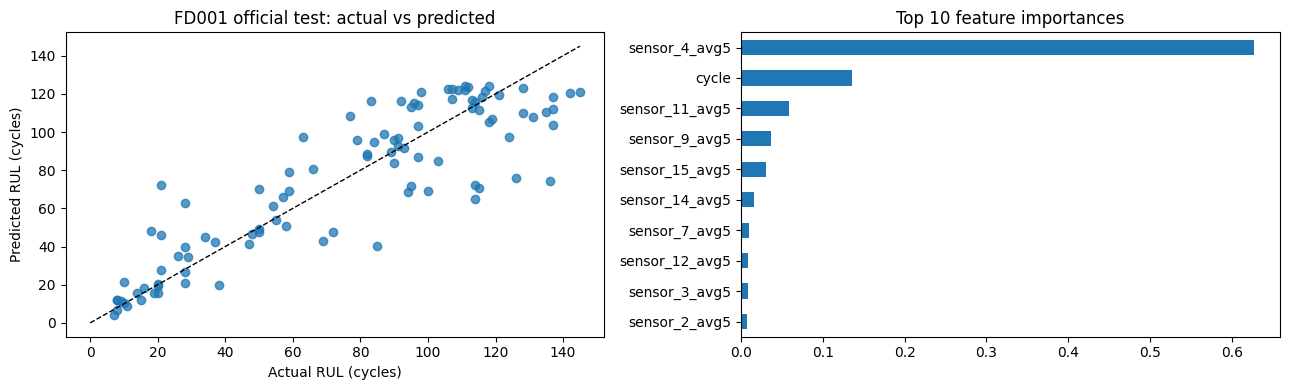

In [10]:
fig,axs=plt.subplots(1,2,figsize=(13,4))
axs[0].scatter(last_test.actual_rul,last_test.predicted_rul,alpha=.75)
maxv=max(last_test.actual_rul.max(),last_test.predicted_rul.max())
axs[0].plot([0,maxv],[0,maxv],linestyle='--',color='black',linewidth=1)
axs[0].set(xlabel='Actual RUL (cycles)',ylabel='Predicted RUL (cycles)',title='FD001 official test: actual vs predicted')
important=pd.Series(final_model.feature_importances_,index=features).nlargest(10).sort_values()
important.plot(kind='barh',ax=axs[1]);axs[1].set_title('Top 10 feature importances')
plt.tight_layout();plt.show()

In [11]:
numeric_similarity=['cycle']+base_columns+[c+'_avg5' for c in base_columns]
scaler=StandardScaler().fit(train_f[numeric_similarity])
Xhist=scaler.transform(train_f[numeric_similarity])
index=NearestNeighbors(n_neighbors=min(100,len(train_f)),metric='euclidean').fit(Xhist)
def similar_states(engine_id,top_k=3):
    selected=last_test[last_test.engine_id==engine_id]
    if len(selected)!=1: raise ValueError('Unknown test engine ID')
    q=scaler.transform(selected[numeric_similarity])
    distances,ix=index.kneighbors(q)
    rows=[];seen=set()
    for distance,pos in zip(distances[0],ix[0]):
        r=train_f.iloc[int(pos)]
        hist_engine=int(r.engine_id)
        if hist_engine in seen:continue
        seen.add(hist_engine)
        rows.append({'historical_engine':hist_engine,'cycle':int(r.cycle),'historical_rul':int(r.rul_raw),'standardized_distance':round(float(distance),3)})
        if len(rows)==top_k:break
    return pd.DataFrame(rows)
DEMO_ENGINE=int(last_test.iloc[0].engine_id)
print('Example test engine:',DEMO_ENGINE)
display(similar_states(DEMO_ENGINE))

Example test engine: 1


,historical_engine,cycle,historical_rul,standardized_distance
0,92,38,303,2.185
1,35,14,167,2.413
2,1,45,147,2.430


In [12]:
knowledge=[
 {'id':'DOC-01','title':'Degradation trend review','text':'For recurring degradation trends, verify signal quality and compare several consecutive operating cycles. Review temperature and pressure drift together rather than diagnosing from one sensor.'},
 {'id':'DOC-02','title':'Vibration investigation','text':'If vibration indications rise over repeated cycles, request qualified inspection of bearings, alignment and mechanical condition. Do not infer a bearing fault from C-MAPSS sensors alone.'},
 {'id':'DOC-03','title':'Compressor performance review','text':'When simulated compressor performance degrades, review related temperature, pressure and corrected-speed channels. Escalate abnormal trends to authorized engineering personnel.'},
 {'id':'DOC-04','title':'Sensor anomaly verification','text':'Before taking action on an unusual sensor measurement, check sensor calibration, data quality, operating conditions, and trends across other channels.'},
 {'id':'DOC-05','title':'Safety and approval','text':'Predicted remaining life is uncertainty-bearing decision support. No safety-critical or maintenance actions may be automatically authorized by the notebook. Use approved site procedures and trained personnel.'}
]
tfidf=TfidfVectorizer(stop_words='english',ngram_range=(1,2))
doc_matrix=tfidf.fit_transform([k['title']+' '+k['text'] for k in knowledge])
def retrieve_documents(query,top_k=3,minimum_score=0.04):
    scores=cosine_similarity(tfidf.transform([query]),doc_matrix).ravel()
    found=[]
    for i in np.argsort(scores)[::-1][:top_k]:
        if scores[i]>=minimum_score:
            found.append({**knowledge[int(i)],'similarity':round(float(scores[i]),3)})
    return found
query='engine compressor degradation with temperature pressure trend and remaining useful life'
for doc in retrieve_documents(query):print(doc['id'],doc['title'],'TF-IDF score:',doc['similarity'])

DOC-01 Degradation trend review TF-IDF score: 0.31
DOC-03 Compressor performance review TF-IDF score: 0.229
DOC-05 Safety and approval TF-IDF score: 0.114


In [13]:
def safe_maintenance_report(engine_id,question='What should be checked for compressor degradation?'):
    if not isinstance(engine_id,(int,np.integer)) or engine_id not in set(last_test.engine_id):
        raise ValueError('Use a valid integer test engine ID.')
    if not isinstance(question,str) or len(question)>500:
        raise ValueError('Question must be a string up to 500 characters.')
    row=last_test.loc[last_test.engine_id==engine_id].iloc[0]
    pred=float(row.predicted_rul)
    if not np.isfinite(pred) or pred<0:raise ValueError('Invalid RUL prediction; stop rather than produce advice.')
    evidence=retrieve_documents(question)
    lines=[f'Engine {engine_id}: estimated remaining useful life {pred:.1f} operating cycles.',
           'This is an uncertain prediction on NASA simulated engine data, not a confirmed failure date.',
           'Closest historical sensor states (different simulated training engines):']
    for _,r in similar_states(engine_id).iterrows():
        lines.append(f"- Engine {int(r.historical_engine)}, cycle {int(r.cycle)}; observed historical RUL {int(r.historical_rul)} cycles; scaled distance {r.standardized_distance:.2f}.")
    if evidence:
        lines.append('Illustrative retrieved guidance (not validated OEM procedures):')
        for d in evidence:
            lines.append(f"- [{d['id']}] {d['title']}: {d['text']}")
    else:
        lines.append('No sufficiently relevant document found. Cannot offer a grounded maintenance recommendation.')
    lines.append('GUARDRAIL: Human engineering review required. Do not automatically stop, operate, or service equipment.')
    return '\n'.join(lines)
print(safe_maintenance_report(DEMO_ENGINE,'compressor temperature pressure degradation trend'))

Engine 1: estimated remaining useful life 123.6 operating cycles.
This is an uncertain prediction on NASA simulated engine data, not a confirmed failure date.
Closest historical sensor states (different simulated training engines):
- Engine 92, cycle 38; observed historical RUL 303 cycles; scaled distance 2.19.
- Engine 35, cycle 14; observed historical RUL 167 cycles; scaled distance 2.41.
- Engine 1, cycle 45; observed historical RUL 147 cycles; scaled distance 2.43.
Illustrative retrieved guidance (not validated OEM procedures):
- [DOC-01] Degradation trend review: For recurring degradation trends, verify signal quality and compare several consecutive operating cycles. Review temperature and pressure drift together rather than diagnosing from one sensor.
- [DOC-03] Compressor performance review: When simulated compressor performance degrades, review related temperature, pressure and corrected-speed channels. Escalate abnormal trends to authorized engineering personnel.
GUARDRAIL: Hu

In [22]:
RUN_OPTIONAL_LLM = True
if RUN_OPTIONAL_LLM:
    from google.colab import userdata
    from google import genai
    api_key = userdata.get('GOOGLE_API_KEY')
    if not api_key: raise ValueError('Set GOOGLE_API_KEY in Colab Secrets first.')
    question = 'What checks are supported by the retrieved notes for compressor degradation?'
    docs = retrieve_documents(question)
    if not docs: raise ValueError('No reliable supporting documents retrieved. Abstaining.')
    context = '\n'.join(f"[{d['id']}] {d['title']}: {d['text']}" for d in docs)
    prompt = f"""You are a prototype maintenance knowledge assistant. Answer ONLY from the supplied context.
Never claim to diagnose a fault, authorize servicing, or predict guaranteed failure dates.
Cite document IDs for all recommendations. If insufficient context, say so.
QUESTION: {question}
CONTEXT:\n{context}"""
    client = genai.Client(api_key=api_key)
    response = client.models.generate_content(model='gemini-3.8-flash', contents=prompt)
    print(response.text)
else:
    print('Optional LLM disabled. TF-IDF retrieval and grounded, rule-based report remain functional.')

Based on the provided context, the supported checks for compressor degradation are:

* **Verify signal quality** [DOC-01].
* **Compare several consecutive operating cycles** [DOC-01].
* **Review temperature and pressure drift together**, rather than relying on a single sensor [DOC-01].
* **Review related temperature, pressure, and corrected-speed channels** when simulated compressor performance degrades [DOC-03].
* **Escalate abnormal trends** to authorized engineering personnel [DOC-03].


DEMO engine 1
Engine 1: estimated remaining useful life 123.6 operating cycles.
This is an uncertain prediction on NASA simulated engine data, not a confirmed failure date.
Closest historical sensor states (different simulated training engines):
- Engine 92, cycle 38; observed historical RUL 303 cycles; scaled distance 2.19.
- Engine 35, cycle 14; observed historical RUL 167 cycles; scaled distance 2.41.
- Engine 1, cycle 45; observed historical RUL 147 cycles; scaled distance 2.43.
Illustrative retrieved guidance (not validated OEM procedures):
- [DOC-01] Degradation trend review: For recurring degradation trends, verify signal quality and compare several consecutive operating cycles. Review temperature and pressure drift together rather than diagnosing from one sensor.
- [DOC-03] Compressor performance review: When simulated compressor performance degrades, review related temperature, pressure and corrected-speed channels. Escalate abnormal trends to authorized engineering personnel.

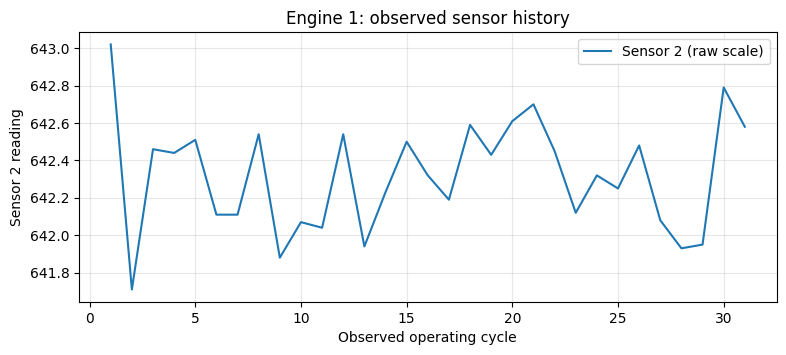

In [15]:
engine_id=DEMO_ENGINE # Change to any available test engine ID, e.g. 1, 2, 3
print('DEMO engine',engine_id)
report=safe_maintenance_report(engine_id,'compressor temperature pressure degradation trend')
print(report)
row=last_test[last_test.engine_id==engine_id].iloc[0]
print(f"\nEvaluation only — official hidden test label: actual RUL {int(row.actual_rul)} cycles, predicted {row.predicted_rul:.1f} cycles")
engine_trace=test_f[test_f.engine_id==engine_id]
plt.figure(figsize=(9,3.5))
plt.plot(engine_trace.cycle,engine_trace.sensor_2,label='Sensor 2 (raw scale)')
plt.xlabel('Observed operating cycle');plt.ylabel('Sensor 2 reading')
plt.title(f'Engine {engine_id}: observed sensor history');plt.grid(alpha=.3);plt.legend();plt.show()